In [ ]:
# IMPORTANT: SOME KAGGLE DATA SOURCES ARE PRIVATE
# RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES.
import kagglehub
kagglehub.login()


In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

vanihari_dataset_path = kagglehub.dataset_download('vanihari/dataset')
vanihari_sketchformer_weights_path = kagglehub.dataset_download('vanihari/sketchformer-weights')

print('Data source import complete.')


**for model building*>>  ***

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.io import loadmat
from PIL import Image
from transformers import GPT2Tokenizer, GPT2LMHeadModel
import torch


2025-09-09 14:02:12.664341: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1757426532.995666      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1757426533.092951      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [ ]:
import os

# Base path
base = "/kaggle/input/dataset"

# See what's inside
print("Contents of /kaggle/input/dataset:")
print(os.listdir(base))

# Check for train/val/test structure
subdir = os.path.join(base, "SketchyScene-7k")  # Just in case it's nested
if os.path.exists(subdir):
    print("\nContents of SketchyScene-7k:")
    print(os.listdir(subdir))


Contents of /kaggle/input/dataset:
['records', 'SketchyScene-7k', 'candidates', 'SketchyScene-Selected3']

Contents of SketchyScene-7k:
['SketchyScene-7k']


In [ ]:
# === SETUP === #

# Fixed dataset paths based on Kaggle's input folder
base_dataset_dir = "/kaggle/input/dataset/SketchyScene-7k/SketchyScene-7k"
records_dir = "/kaggle/input/dataset/records"

# Main directories
train_dir = os.path.join(base_dataset_dir, "train")
class_gt_dir = os.path.join(train_dir, "CLASS_GT")
json_layout_dir = os.path.join(records_dir, "train/skenew/results1")
image_dir = os.path.join(records_dir, "train/skenew/results3")


Found 5617 .mat files.


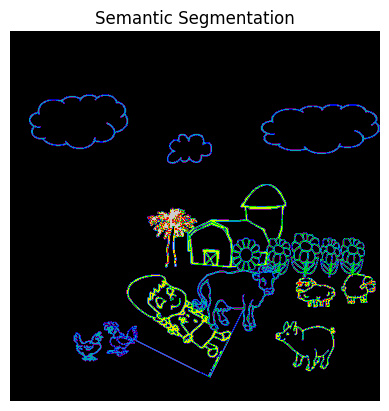

In [ ]:
# === STEP 1: Explore Segmentation Data === #

mat_files = sorted([f for f in os.listdir(class_gt_dir) if f.endswith(".mat")])
print(f"Found {len(mat_files)} .mat files.")

sample_mat_path = os.path.join(class_gt_dir, mat_files[0])
mat_data = loadmat(sample_mat_path)
seg_map = mat_data.get("CLASS_GT", next(iter(mat_data.values())))

plt.imshow(seg_map, cmap='nipy_spectral')
plt.title("Semantic Segmentation")
plt.axis("off")
plt.show()

In [ ]:
from collections import Counter
from collections import defaultdict

In [ ]:
import json


In [ ]:

# === STEP 2: Read and Analyze JSON Layouts === #

json_files = sorted([f for f in os.listdir(json_layout_dir) if f.endswith('.json')])
category_counter = Counter()
category_examples = defaultdict(list)
object_counts = []

for fname in json_files:
    with open(os.path.join(json_layout_dir, fname)) as f:
        data = json.load(f)
        object_counts.append(len(data))
        for obj in data:
            cat = obj.get("category", "unknown")
            category_counter[cat] += 1
            if len(category_examples[cat]) < 3:
                category_examples[cat].append(obj)

print(f"\nTop 5 categories:")
for cat, count in category_counter.most_common(5):
    print(f"{cat}: {count} objects")


Top 5 categories:
grass: 21031 objects
tree: 15310 objects
cloud: 11004 objects
flower: 7004 objects
house: 3380 objects


In [ ]:
# === STEP 3: Prompt Generation === #

def generate_prompt(layout):
    desc = []
    for obj in layout:
        cat = obj['category']
        x = obj.get("left", "0").replace("px", "")
        y = obj.get("top", "0").replace("px", "")
        try:
            loc = f"{cat} at ({int(x)},{int(y)})"
        except:
            loc = cat
        desc.append(loc)
    return "A scene with: " + ", ".join(desc) + "."


In [ ]:
# === STEP 4: Build Unified Dataset === #

dataset = []

for fname in json_files:
    image_id = fname.replace(".json", "")
    image_path = os.path.join(image_dir, f"{image_id}.png")
    if not os.path.exists(image_path):
        continue

    with open(os.path.join(json_layout_dir, fname)) as f:
        layout = json.load(f)

    prompt = generate_prompt(layout)

    dataset.append({
        "id": image_id,
        "text_prompt": prompt,
        "object_layout": layout,
        "sketch_image_path": image_path
    })

print(f"\n✅ Built unified dataset with {len(dataset)} samples.")


✅ Built unified dataset with 5604 samples.


In [ ]:
# === STEP 6: Save Dataset to JSON === #

save_path = "/kaggle/working/sketchformer_dataset.json"
with open(save_path, "w") as f:
    json.dump(dataset, f, indent=2)

print(f"\n✅ Saved {len(dataset)} entries to {save_path}")



✅ Saved 5604 entries to /kaggle/working/sketchformer_dataset.json


In [ ]:
import random



📝 Prompt: A scene with: cloud at (150,50), cloud at (50,50), house at (220,90), tree at (410,120), tree at (130,290), tree at (570,220), bench at (250,480), street_lamp at (110,170), pig at (300,440), sun at (620,50), chicken at (80,530), chicken at (490,580), dog at (240,200), bird at (230,310), bird at (450,50).
🧩 Objects: ['cloud', 'cloud', 'house', 'tree', 'tree', 'tree', 'bench', 'street_lamp', 'pig', 'sun', 'chicken', 'chicken', 'dog', 'bird', 'bird']


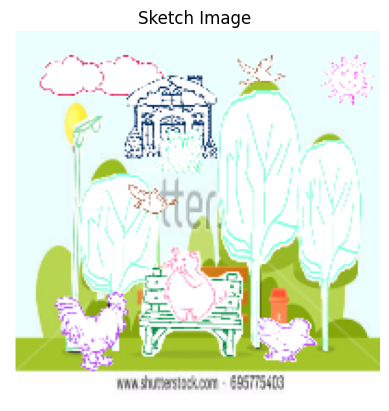

In [ ]:
# === STEP 7: Sample Visualization === #

sample = random.choice(dataset)
print("\n📝 Prompt:", sample['text_prompt'])
print("🧩 Objects:", [obj['category'] for obj in sample['object_layout']])
# Display image inline in notebook
img = Image.open(sample['sketch_image_path'])
plt.imshow(img)
plt.axis('off')
plt.title('Sketch Image')
plt.show()

In [ ]:
from pathlib import Path

root = Path("/kaggle/input/dataset/SketchyScene-Selected3/SketchyScene-Selected3/train_selectedsamples/DRAWING_GT_VIS")
subdirs = sorted([p for p in root.iterdir() if p.is_dir()])
print(f"Sample folders: {[d.name for d in subdirs[:5]]}")

# Now look inside a couple of these folders
for folder in subdirs[:5]:
    files = list(folder.glob("*.png"))
    print(f"📁 Folder: {folder.name} | PNGs: {[f.name for f in files]}")


Sample folders: ['1', '10', '100', '1000', '1001']
📁 Folder: 1 | PNGs: ['L0_sample1_10.png', 'L0_sample1_11.png', 'L0_sample1_6.png']
📁 Folder: 10 | PNGs: ['L0_sample10_11.png', 'L0_sample10_9.png', 'L0_sample10_7.png']
📁 Folder: 100 | PNGs: ['L0_sample100_15.png', 'L0_sample100_2.png', 'L0_sample100_27.png']
📁 Folder: 1000 | PNGs: ['L0_sample1000_14.png', 'L0_sample1000_20.png', 'L0_sample1000_25.png']
📁 Folder: 1001 | PNGs: ['L0_sample1001_4.png', 'L0_sample1001_3.png', 'L0_sample1001_14.png']


In [ ]:
import os
import json
from pathlib import Path
from tqdm import tqdm

# === Paths ===
json_root = Path("/kaggle/input/dataset/records/train/skenew/results1")
image_root = Path("/kaggle/input/dataset/SketchyScene-Selected3/SketchyScene-Selected3/train_selectedsamples/DRAWING_GT_VIS")

# === Output ===
dataset = []

# === Category Parser ===
def get_prompt_from_json(json_path):
    with open(json_path) as f:
        data = json.load(f)
    categories = [obj['category'] for obj in data]
    prompt = "A scene with: " + ", ".join(sorted(set(categories)))
    return prompt

# === Scan and Match ===
for json_file in tqdm(sorted(json_root.glob("*.json"))):
    scene_id = json_file.stem
    scene_dir = image_root / scene_id

    if not scene_dir.exists():
        continue

    images = sorted(scene_dir.glob("*.png"))
    if not images:
        continue

    prompt = get_prompt_from_json(json_file)

    for img_path in images:
        dataset.append({
            "image": str(img_path),
            "prompt": prompt
        })

# === Save ===
out_path = "/kaggle/working/scene_prompt_dataset.json"
with open(out_path, "w") as f:
    json.dump(dataset, f, indent=2)

print(f"✅ Saved {len(dataset)} image-prompt pairs to {out_path}")


100%|██████████| 5617/5617 [00:36<00:00, 152.57it/s]

✅ Saved 16846 image-prompt pairs to /kaggle/working/scene_prompt_dataset.json


In [ ]:
# Reinstall numpy
!pip install numpy==1.24.4 --force-reinstall --no-cache-dir

# Reinstall scikit-learn
!pip install --force-reinstall --no-cache-dir scikit-learn

# Clear Python bytecode cache
!find . -type f -name "*.pyc" -delete

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 236.6 MB/s eta 0:00:00a 0:00:01
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.8.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
gensim 4.3.3 requires scipy<1.14.0,>=1.7.0, but you have scipy 1.15.3 which is incompatible.
mkl-umath 0.1.1 requires numpy<1.27.0,>=1.26.4, but you have numpy 1.24.4 which is incompatible.
mkl-random 1.2.4 requires numpy<1.27.0,>=1.26.4, but you have numpy 1.24.4 which is incompatible.
mkl-fft 1.3.8 requires numpy<1.27.0,>=1.26.4, but you have numpy 1.24.4 which is incompatible.
datasets 3.6.0 requires fsspec[http]<=2025.3.0,>=2023.1.0, but you have fsspec 2025.5.1 which is incompatib

In [ ]:
from diffusers import StableDiffusionPipeline
import torch

# Model ID from Hugging Face Hub
model_id = "sd-legacy/stable-diffusion-v1-5"

# Load the pipeline (you can set torch_dtype=torch.float16 if using GPU with float16 support)
pipe = StableDiffusionPipeline.from_pretrained(model_id, torch_dtype=torch.float16)
pipe = pipe.to("cuda")  # Use "cuda" for GPU or "cpu" for CPU


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

vocab.json: 0.00B [00:00, ?B/s]

unet/diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

In [ ]:
# 2️⃣ Load dataset and prepare dataloader
from datasets import load_dataset
from torchvision import transforms
from PIL import Image
from torch.utils.data import DataLoader
import torch
from tqdm import tqdm
from diffusers import StableDiffusionPipeline
from torch.optim import AdamW
from diffusers.optimization import get_scheduler
import os

# Load dataset
ds = load_dataset("json", data_files="/kaggle/working/scene_prompt_dataset.json")["train"]

img_transforms = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.CenterCrop((512,512)),
    transforms.ToTensor(),
    transforms.Normalize([0.5,0.5,0.5],[0.5,0.5,0.5])
])

def preprocess_example(example):
    image = Image.open(example["image"]).convert("RGB")
    example["pixel_values"] = img_transforms(image)
    example["caption"] = example.get("caption", example.get("prompt", ""))
    return example

ds = ds.map(preprocess_example)
ds = ds.remove_columns([c for c in ds.column_names if c not in ("pixel_values", "caption")])
ds.set_format(type="torch", columns=["pixel_values", "caption"])

dataloader = DataLoader(ds, batch_size=2, shuffle=True)
print(f"✅ Dataset ready with {len(ds)} samples")

# 3️⃣ Load Stable Diffusion model
device = "cuda" if torch.cuda.is_available() else "cpu"
pipe = StableDiffusionPipeline.from_pretrained(
    "sd-legacy/stable-diffusion-v1-5",
    torch_dtype=torch.float16
).to(device)

# Access components
unet = pipe.unet
text_encoder = pipe.text_encoder
tokenizer = pipe.tokenizer
vae = pipe.vae
scheduler = pipe.scheduler

# 4️⃣ Optimizer & Scheduler
optimizer = AdamW(unet.parameters(), lr=5e-6)
lr_scheduler = get_scheduler("constant", optimizer=optimizer)

# 5️⃣ Training Loop
num_epochs = 3  # change as needed
unet.train()

for epoch in range(num_epochs):
    for batch in tqdm(dataloader, desc=f"Epoch {epoch+1}/{num_epochs}"):
        pixel_values = batch["pixel_values"].to(device, dtype=torch.float16)
        captions = batch["caption"]

        # Tokenize captions
        inputs = tokenizer(
            captions,
            padding="max_length",
            truncation=True,
            max_length=tokenizer.model_max_length,
            return_tensors="pt"
        )
        input_ids = inputs.input_ids.to(device)

        # Encode text
        encoder_hidden_states = text_encoder(input_ids)[0]

        # Encode images to latents
        latents = vae.encode(pixel_values).latent_dist.sample() * 0.18215

        # Create noise and noisy latents
        noise = torch.randn_like(latents)
        timesteps = torch.randint(0, 1000, (latents.shape[0],), device=device).long()
        noisy_latents = scheduler.add_noise(latents, noise, timesteps)

        # Predict noise
        noise_pred = unet(noisy_latents, timesteps, encoder_hidden_states).sample

        # Loss
        loss = torch.nn.functional.mse_loss(noise_pred, noise)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        lr_scheduler.step()

    print(f"Epoch {epoch+1} finished. Loss: {loss.item():.4f}")

print("✅ Training complete!")

# 6️⃣ Save the fine-tuned model
save_dir = "/kaggle/working/finetuned_model"
os.makedirs(save_dir, exist_ok=True)
pipe.save_pretrained(save_dir)
tokenizer.save_pretrained(save_dir)

print(f"💾 Model saved to {save_dir}")

Generating train split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/16846 [00:00<?, ? examples/s]

✅ Dataset ready with 16846 samples


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Epoch 1/3: 100%|██████████| 8423/8423 [2:46:57<00:00,  1.19s/it]  


Epoch 1 finished. Loss: nan


Epoch 2/3: 100%|██████████| 8423/8423 [2:47:21<00:00,  1.19s/it]  


Epoch 2 finished. Loss: nan


Epoch 3/3: 100%|██████████| 8423/8423 [2:47:04<00:00,  1.19s/it]  


Epoch 3 finished. Loss: nan
✅ Training complete!
💾 Model saved to /kaggle/working/finetuned_model


In [ ]:
import torch
from diffusers import StableDiffusionPipeline
from PIL import Image

# Load your finetuned model
model_path = "/kaggle/working/finetuned_model"
pipe = StableDiffusionPipeline.from_pretrained(
    model_path,
    torch_dtype=torch.float16
).to("cuda")

while True:
    prompt = input("📝 Enter your prompt (or 'quit' to exit): ")
    if prompt.lower() in ["quit", "exit"]:
        break

    print(f"🔹 Generating for: {prompt}")
    image = pipe(prompt).images[0]

    # Save and display
    save_path = "/kaggle/working/output.png"
    image.save(save_path)
    display(image)  # works in Kaggle/Colab

    print(f"✅ Image saved at {save_path}")


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]